# Solar light deflection — Figures 2a and 2b

Reproduce the solar contribution to the astrometric correction amplitude
$C_E$ in Figure 2 of the accompanying article. Definitions and derivations
are given in the article; this notebook documents the numerical implementation.

| Panel | Independent variable | Curves | Output |
|---|---|---|---|
| 2a | Solar separation $\psi_\odot$ | Target distances 0.1, 0.5, 1 and 40 au | `C_E_psi.pdf` |
| 2b | Observer-to-target distance $D_E$ | Ten fixed solar separations | `C_E_D_E.pdf` |

**Requirements.** NumPy, Astropy and Matplotlib, with the repository's
`light_deflection.py` in the same directory or on the Python path. No ephemeris
kernel, SPICE installation or reference epoch is needed. Restart the Python
kernel and run all cells in order. Both PDFs are saved in the working directory;
existing files with those names are overwritten.


In [1]:
import numpy as np
import astropy.units as u
import astropy.constants as const
import matplotlib.pyplot as plt

from light_deflection import calc_alpha_star, calc_alpha_E


## Shared model parameters

Fix the observer-to-Sun distance at $D_\odot=1$ au and place the star at
infinity in both panels. The stellar deflection is evaluated directly with
`calc_alpha_star`, which implements the source-at-infinity limit.

The occulting target remains at the finite distance $D_E$ and its deflection
is evaluated with `calc_alpha_E`. Both functions adopt $\gamma=1$ and return
angular amplitudes in mas. The solar GM expression is unchanged.


In [2]:
sun_distance = 1 * u.au
sun_GM = (const.G * (1 * u.M_sun)).to(u.km**3 / u.s**2)


## Shared vectorized calculation

For each solar separation $\psi_\odot$, the star and target have the same
geometric sightline. Their monopole deflection vectors consequently point
along the same tangent-plane direction. The correction amplitude reduces to
$$C_E=D_E\left|\alpha_E-\alpha_\star\right|,$$
with the angular difference expressed in radians. This reduction applies to
the aligned geometry of these two panels; a general event with distinct star
and target directions requires the vector difference.

The stellar amplitude is evaluated in the infinite-distance limit once per
separation; broadcasting evaluates the finite-target amplitudes for the entire
grid. Distances occupy axis 0 and separations occupy axis 1.

Only the solar monopole is included, with $\gamma=1$. No solar-disk or
visibility cut is applied: these are idealized curves, including separations
inside the apparent solar disk. Exact alignments at 0 and 180 degrees are
excluded; the latter also gives a zero correction unsuitable for a log axis.


In [3]:
def solar_correction_grid(sun_distance, gm, target_distances, psi):
    """Return solar C_E for a finite target aligned with a star at infinity.

    Parameters
    ----------
    sun_distance : astropy.units.Quantity
        Positive observer-to-Sun distance (scalar); set to 1 au in both panels.
    gm : astropy.units.Quantity
        Solar gravitational parameter, with length**3 / time**2 units.
    target_distances : astropy.units.Quantity
        One-dimensional array of positive observer-to-target distances.
    psi : astropy.units.Quantity
        One-dimensional array of solar separations, strictly between 0 and pi.

    Returns
    -------
    astropy.units.Quantity
        Correction amplitudes in km, shape (n_distances, n_separations).
        Rows correspond to target_distances and columns to psi.

    Notes
    -----
    For this aligned geometry, C_E = D_E * abs(alpha_E - alpha_star).
    The angular difference is converted to numerical radians before
    multiplying by distance. No finite stellar-distance parameter is used.
    """
    distances = u.Quantity(target_distances).to(u.au)
    sun_distance = u.Quantity(sun_distance).to(u.au)
    psi = u.Quantity(psi).to(u.rad)
    if distances.ndim != 1 or psi.ndim != 1:
        raise ValueError('target_distances and psi must be one-dimensional.')
    if not sun_distance.isscalar:
        raise ValueError('sun_distance must be scalar.')
    if np.any(distances <= 0*u.au) or sun_distance <= 0*u.au:
        raise ValueError('Sun and target distances must be positive.')
    if np.any((psi <= 0*u.rad) | (psi >= np.pi*u.rad)):
        raise ValueError('Solar separations must lie strictly between 0 and pi radians.')

    alpha_star = calc_alpha_star(gm, sun_distance, psi)
    alpha_target = calc_alpha_E(gm, sun_distance, distances[:, np.newaxis], psi)
    delta_alpha_rad = np.abs(alpha_target - alpha_star).to_value(
        u.rad, equivalencies=u.dimensionless_angles()
    )
    return (distances[:, np.newaxis] * delta_alpha_rad).to(u.km)


## Figure 2a — Varying solar separation

Use four fixed target distances and 361 monotonically increasing separations.
The angular extent matches the original notebook: 0.001 to $\pi-0.0045$
radians. The star is treated at infinity.


In [4]:
target_distances_a = np.array([0.1, 0.5, 1.0, 40.0]) * u.au
psi_grid_a = np.linspace(0.001, np.pi - 0.0045, 361) * u.rad

corrections_a = solar_correction_grid(
    sun_distance, sun_GM, target_distances_a, psi_grid_a
)


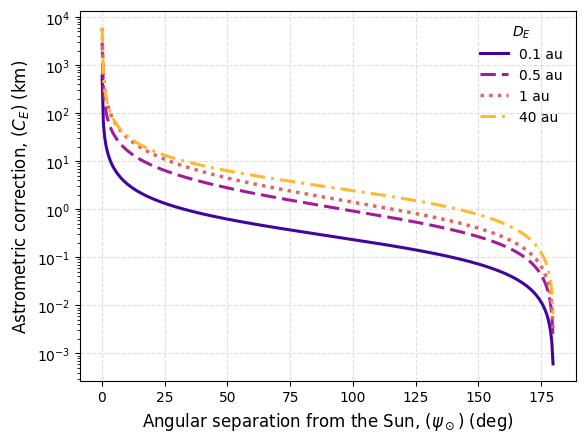

In [5]:
colors_a = plt.cm.plasma(np.linspace(0.1, 0.85, len(target_distances_a)))
styles_a = ['-', (0, (5, 2)), (0, (1, 1.5)), (0, (5, 2, 1, 2))]
widths_a = [2.2, 2.2, 2.5, 2.2]

fig_a, ax_a = plt.subplots(figsize=(6.4, 4.8))
ax_a.set_yscale('log')
for i, (distance, curve, color) in enumerate(zip(target_distances_a, corrections_a, colors_a)):
    j = i % len(styles_a)
    ax_a.plot(psi_grid_a.to_value(u.deg), curve.to_value(u.km),
              color=color, linestyle=styles_a[j], linewidth=widths_a[j],
              label=f'{distance.to_value(u.au):g} au')

ax_a.set_xlabel(r'Angular separation from the Sun, $(\psi_\odot)$ (deg)', fontsize=12)
ax_a.set_ylabel(r'Astrometric correction, $(C_E)$ (km)', fontsize=12)
ax_a.grid(True, linestyle='--', alpha=0.4)
ax_a.legend(title=r'$D_E$', loc='upper right', frameon=False)
fig_a.savefig('C_E_psi.pdf', bbox_inches='tight')
plt.show()


## Figure 2b — Varying observer-to-target distance

Use 500 linearly spaced distances from 0.1 to 50 au and ten
fixed solar separations. A logarithmic x-axis changes the display. The star is treated at infinity.

`corrections_b` has shape (500, 10). Transpose it in the plotting loop so that
each curve corresponds to one fixed separation. The plot uses logarithmic
axes and preserves the original colors and sequence of line styles.

The shaded population bands are retained as optional illustrative annotations. Their numerical limits are **not population
boundaries in observer-to-target distance**: orbital populations are normally
described using heliocentric/orbital quantities, whereas this axis is $D_E$.
These bands do not enter the calculation and do not classify the simulated
targets. Set `show_population_bands=False` to omit them.


In [6]:
target_distance_grid_b = np.linspace(0.1, 50, 500) * u.au
angular_separations_b = np.array([0.1, 1, 5, 10, 20, 45, 90, 120, 150, 175]) * u.deg

corrections_b = solar_correction_grid(
    sun_distance, sun_GM, target_distance_grid_b, angular_separations_b
)


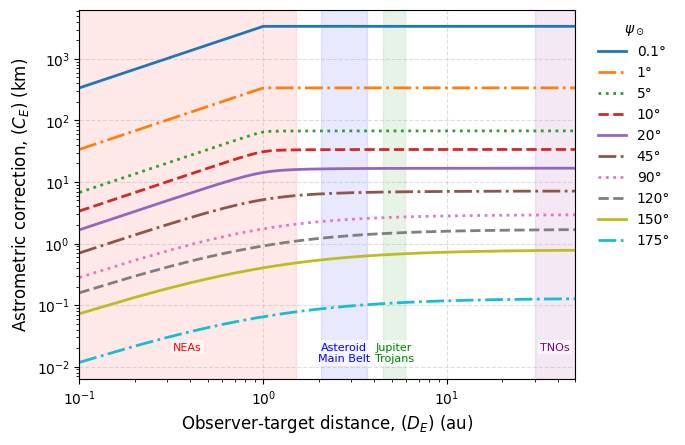

In [7]:
colors_b = plt.cm.tab10(np.linspace(0, 1, len(angular_separations_b)))
styles_b = ['-', '-.', ':', '--']
show_population_bands = True

fig_b, ax_b = plt.subplots(figsize=(6.4, 4.8))
ax_b.set_xscale('log')
ax_b.set_yscale('log')
for i, (separation, curve, color) in enumerate(zip(angular_separations_b, corrections_b.T, colors_b)):
    ax_b.plot(target_distance_grid_b.to_value(u.au), curve.to_value(u.km),
              color=color, linestyle=styles_b[i % len(styles_b)], linewidth=2,
              label=f'{separation.to_value(u.deg):g}°')

if show_population_bands:
    # Illustrative intervals retained from the original notebook; see note above.
    regions = [
        (0.1, 1.5, 'NEAs', 'red'),
        (2.06, 3.65, 'Asteroid\nMain Belt', 'blue'),
        (4.5, 5.9, 'Jupiter\nTrojans', 'green'),
        (30, 50, 'TNOs', 'purple'),
    ]
    for start, end, label, color in regions:
        ax_b.axvspan(start, end, alpha=0.09, color=color)
        ax_b.text(np.sqrt(start*end), 0.10, label,
                  transform=ax_b.get_xaxis_transform(), color=color, fontsize=8,
                  ha='center', va='top',
                  bbox=dict(facecolor='white', edgecolor='none', alpha=0.6, pad=1.5))

ax_b.set_xlim(0.1, 50)
ax_b.set_xlabel(r'Observer-target distance, $(D_E)$ (au)', fontsize=12)
ax_b.set_ylabel(r'Astrometric correction, $(C_E)$ (km)', fontsize=12)
ax_b.grid(True, linestyle='--', alpha=0.4)
ax_b.legend(title=r'$\psi_\odot$', loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
fig_b.savefig('C_E_D_E.pdf', bbox_inches='tight')
plt.show()
